| Integrante | Matrícula |
|---|---|
| César Santiago Esparza Guzmán | 2184325 |
| Rodríguez Chaires Raúl Cristóbal | 2201389 |
| Jorge Daniel García Ortiz | 2189190 |
| Nicolás García Pinto | 2188223 |
| David Lazos Ramírez | 2276044 |
| Jesús Rodrigo Alemán Marines | 2153639 |

# Clasificación de tumores de mama con un Árbol de Decisión

**Dataset:** Breast Cancer Wisconsin (Diagnostic).
**Objetivo:** clasificar cada tumor como **maligno (1)** o **benigno (0)** a partir de 30 características numéricas calculadas sobre imágenes de núcleos celulares.

Pipeline: carga → análisis exploratorio → limpieza (nulos y outliers por IQR) → entrenamiento y evaluación de un `DecisionTreeClassifier`.

## 0. Imports y configuración

Se importan únicamente las librerías requeridas (pandas, NumPy, Matplotlib y scikit-learn) y se fija `RANDOM_STATE = 42` para que todos los resultados sean reproducibles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

RANDOM_STATE = 42

## 1. Carga del conjunto de datos

Se usa `load_breast_cancer(as_frame=True)` de scikit-learn, que devuelve el dataset de UCI ya con los nombres de las 30 columnas. Esta versión no incluye la columna de ID; el diagnóstico viene en la columna `target`.

**Importante:** en scikit-learn `target` está codificado como **0 = maligno, 1 = benigno**, al revés de lo que se pide. Se crea la columna `diagnosis` con la convención del proyecto (**1 = Maligno, 0 = Benigno**) y se elimina `target` para evitar confusiones.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

# Invertir la etiqueta de sklearn: 1 = Maligno, 0 = Benigno
df["diagnosis"] = 1 - df["target"]
df = df.drop(columns="target")

print("Clases originales de sklearn:", data.target_names.tolist())
print("Shape:", df.shape)
df.head()

Clases originales de sklearn: ['malignant', 'benign']
Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Análisis exploratorio y visualización

Antes de modelar se revisa la estructura del dataset: estadísticas descriptivas (conteo, media, desviación estándar, mínimo, cuartiles y máximo), tipos de datos, valores nulos, filas duplicadas y el balance de clases.

Después se grafica `mean radius` contra `mean texture`, separando benignos y malignos por color, para ver si hay separación visual entre las clases.

In [3]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [5]:
print("Valores nulos por columna (total):", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("\nDistribución de clases (1 = Maligno, 0 = Benigno):")
print(df["diagnosis"].value_counts())

Valores nulos por columna (total): 0
Filas duplicadas: 0

Distribución de clases (1 = Maligno, 0 = Benigno):
diagnosis
0    357
1    212
Name: count, dtype: int64


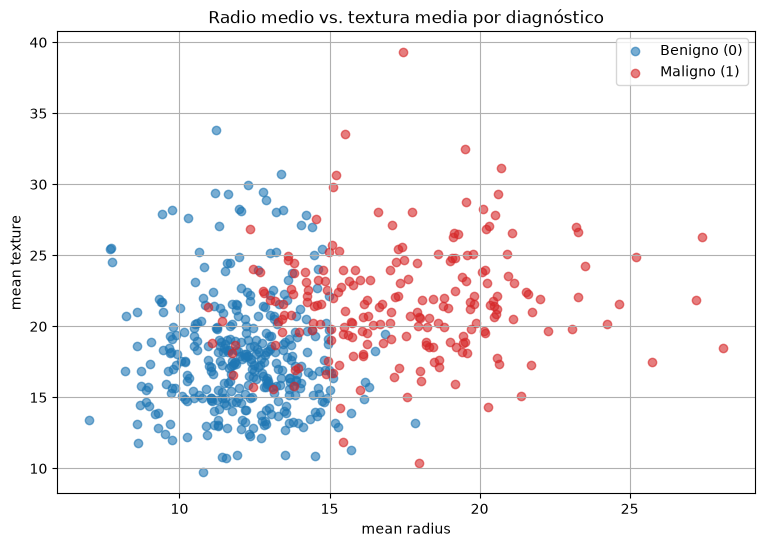

In [6]:
benigno = df[df["diagnosis"] == 0]
maligno = df[df["diagnosis"] == 1]

plt.figure(figsize=(9, 6))
plt.scatter(benigno["mean radius"], benigno["mean texture"], c="tab:blue", alpha=0.6, label="Benigno (0)")
plt.scatter(maligno["mean radius"], maligno["mean texture"], c="tab:red", alpha=0.6, label="Maligno (1)")
plt.xlabel("mean radius")
plt.ylabel("mean texture")
plt.title("Radio medio vs. textura media por diagnóstico")
plt.legend()
plt.grid(True)
plt.show()

**Observación:** los tumores malignos tienden a tener un radio medio mayor que los benignos, aunque ambas clases se traslapan en la zona intermedia. La textura por sí sola separa menos que el radio.

## 3. Limpieza y preprocesamiento

### 3.1 Valores nulos
Se buscan valores `NaN` y también celdas vacías o con solo espacios, que convertimos a `NaN` antes de contarlas.

**Estrategia:** si aparecen nulos y son un porcentaje mínimo (< 5 % de las filas), se eliminan esas filas, porque perder tan pocas observaciones no afecta al modelo. Si fueran más, se imputaría con la **mediana** de cada columna, que es robusta a outliers. Como se ve en la salida, el dataset **no tiene nulos**, así que no hace falta eliminar ni imputar nada.

In [7]:
df_check = df.replace(r"^\s*$", np.nan, regex=True)
n_nulls = df_check.isnull().sum()
total_nulls = n_nulls.sum()

print("Columnas con nulos:")
print(n_nulls[n_nulls > 0] if total_nulls > 0 else "Ninguna")
print(f"Total de valores nulos: {total_nulls}")
print(f"Porcentaje de filas con algún nulo: {df_check.isnull().any(axis=1).mean() * 100:.2f}%")

Columnas con nulos:
Ninguna
Total de valores nulos: 0
Porcentaje de filas con algún nulo: 0.00%


### 3.2 Outliers en `mean area` (método IQR)
Se calcula el rango intercuartílico con NumPy:

- IQR = Q3 − Q1
- Límite inferior = Q1 − 1.5·IQR
- Límite superior = Q3 + 1.5·IQR

Se conservan solo las filas cuyo `mean area` está dentro de esos límites. El resultado se guarda en `df_clean`, sin sobrescribir `df`, para poder comparar el antes y el después.

In [8]:
q1, q3 = np.percentile(df["mean area"], [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df_clean = df[(df["mean area"] >= lower) & (df["mean area"] <= upper)]

print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Límite inferior = {lower:.2f}, límite superior = {upper:.2f}")
print(f"Filas antes del filtro:  {len(df)}")
print(f"Filas después del filtro: {len(df_clean)}")
print(f"Filas eliminadas: {len(df) - len(df_clean)}")
print("\nDistribución de clases después del filtro:")
print(df_clean["diagnosis"].value_counts())

Q1 = 420.30, Q3 = 782.70, IQR = 362.40
Límite inferior = -123.30, límite superior = 1326.30
Filas antes del filtro:  569
Filas después del filtro: 544
Filas eliminadas: 25

Distribución de clases después del filtro:
diagnosis
0    357
1    187
Name: count, dtype: int64


**Observación:** los 25 outliers eliminados son tumores **malignos** con área muy grande (el límite inferior es negativo, así que solo se recortan valores altos). Por eso el filtro baja los malignos de 212 a 187 y cambia un poco la proporción de clases en los datos limpios.

**Escalado:** no se aplica `StandardScaler` porque un árbol de decisión divide por umbrales en cada variable y no le afecta la escala de las características.

## 4. Entrenamiento y evaluación del árbol de decisión

- **X:** las 30 características numéricas (sin ID ni diagnóstico).
- **y:** `diagnosis`, con **1 = Maligno** y **0 = Benigno**.
- **Split:** 75 % entrenamiento y 25 % prueba (`test_size=0.25`, `random_state=42`).
- **Modelo:** `DecisionTreeClassifier(random_state=42)` con los hiperparámetros por defecto.

Se evalúa con accuracy y con `classification_report` (precision, recall y f1 por clase). En este problema el **recall de la clase Maligno** es la métrica más importante, porque un falso negativo es un cáncer que no se detecta.

In [9]:
X = df_clean.drop(columns="diagnosis")
y = df_clean["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nConteo de y (1 = Maligno, 0 = Benigno):")
print(y.value_counts())

X shape: (544, 30)
y shape: (544,)

Conteo de y (1 = Maligno, 0 = Benigno):
diagnosis
0    357
1    187
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (408, 30) | X_test: (136, 30)


In [11]:
model = DecisionTreeClassifier(random_state=RANDOM_STATE)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

Accuracy: 0.9118

              precision    recall  f1-score   support

     Benigno       0.91      0.94      0.93        79
     Maligno       0.91      0.88      0.89        57

    accuracy                           0.91       136
   macro avg       0.91      0.91      0.91       136
weighted avg       0.91      0.91      0.91       136



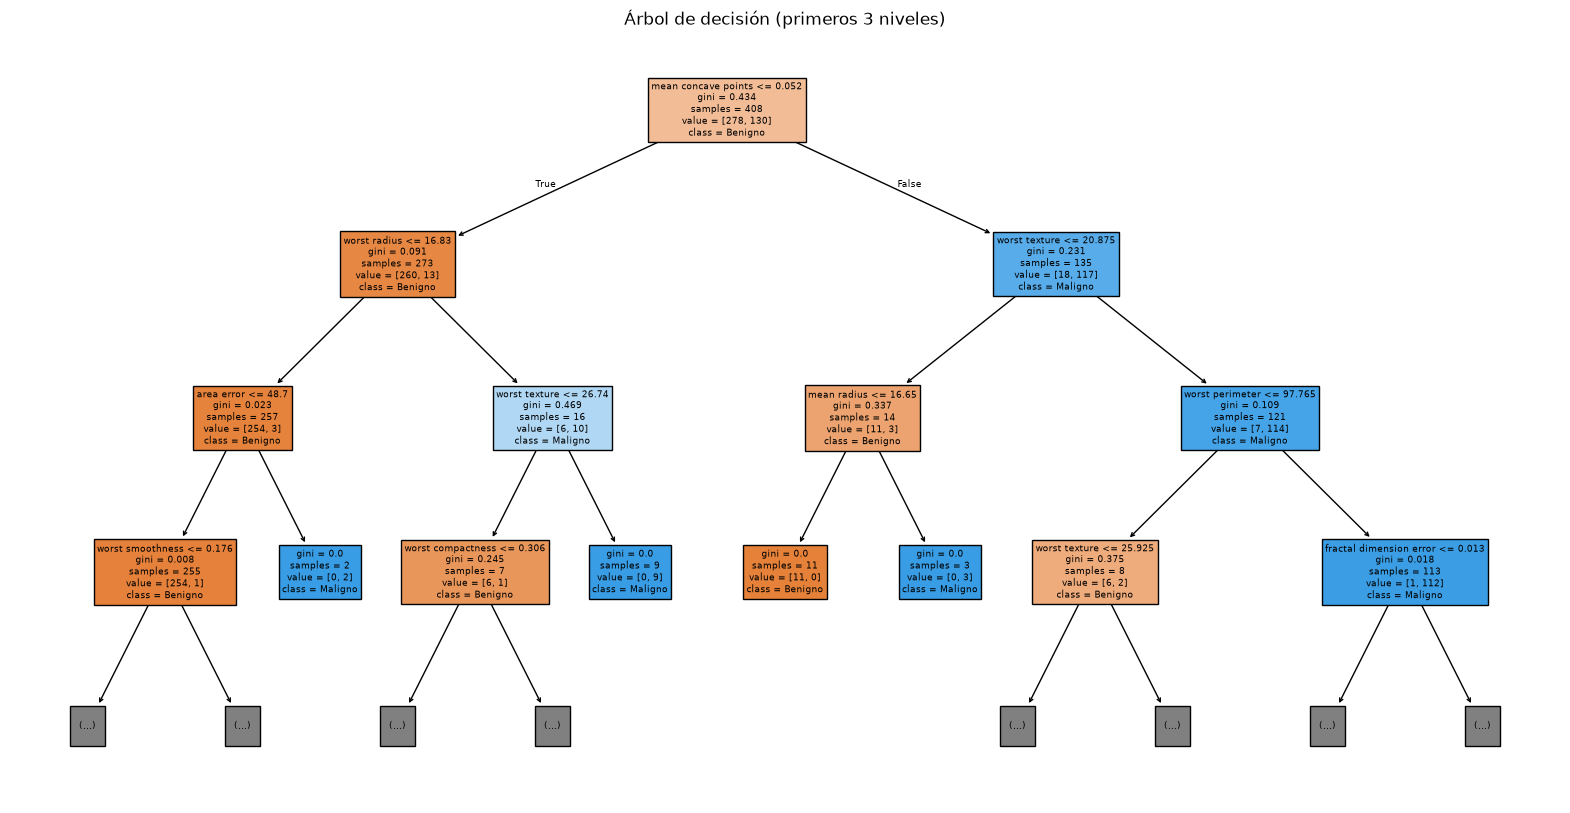

In [12]:
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Benigno", "Maligno"],
    filled=True,
    max_depth=3,
)
plt.title("Árbol de decisión (primeros 3 niveles)")
plt.show()

**Lectura del árbol:** cada nodo muestra la condición de división, el índice Gini, el número de muestras y la clase mayoritaria. Los colores naranjas indican predominio de Benigno y los azules de Maligno. Solo se dibujan los primeros 3 niveles para que sea legible; el árbol completo es más profundo porque no tiene poda.